# Imports

In [43]:
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np
from scipy import linalg
from scipy.optimize import minimize
from scipy.ndimage import gaussian_laplace, maximum_filter

# Question 1

In [2]:
img = cv.imread("images/the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)

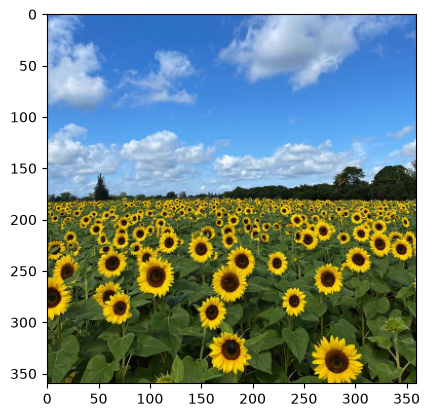

In [3]:
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

In [107]:
grayImg = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
grayImg = grayImg.astype(np.float32) / 255.0

In [142]:
sigma_min = 1
sigma_max = 12
num_scales = 25
thes = 0.5
sigmas = np.linspace(sigma_min, sigma_max, num_scales)

In [143]:
scale_space = np.stack([
    sigma**2 * gaussian_laplace(grayImg, sigma=sigma)
    for sigma in sigmas
], axis=0)

scale_space = np.maximum(scale_space, 0)

In [144]:
local_max = maximum_filter(scale_space, size=(3, 5, 5))
threshold = thes * scale_space.max()
peaks = (scale_space == local_max) & (scale_space > threshold)

scale_ids, ys, xs = np.where(peaks)
blobs = [(int(x), int(y), float(sigmas[k]), float(np.sqrt(2) * sigmas[k]))
         for k, y, x in zip(scale_ids, ys, xs)]
blobs.sort(key=lambda b: b[3], reverse=True)

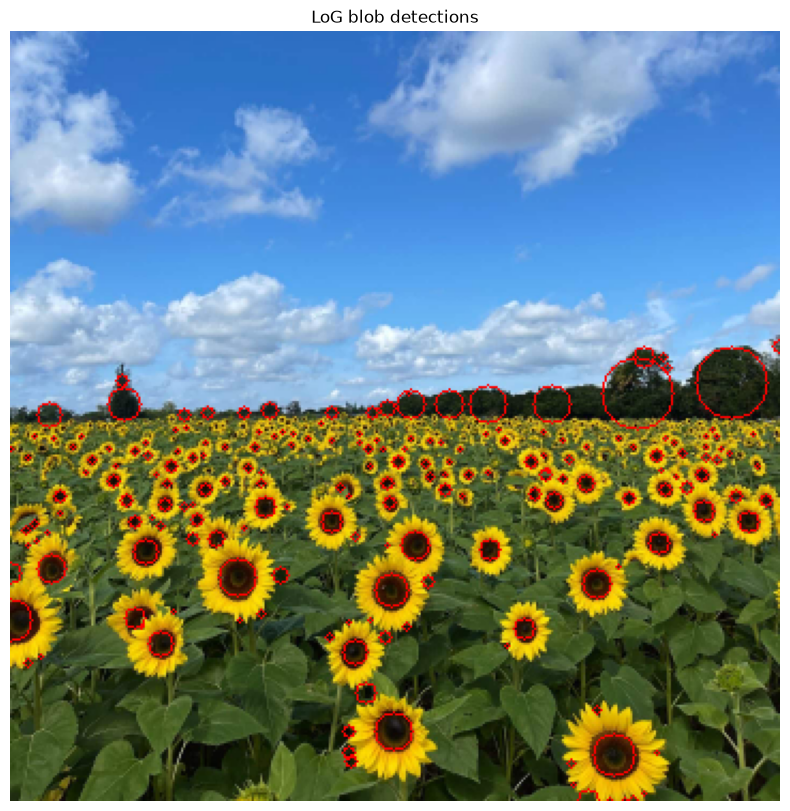

Sigma range: 1.0 to 12.0
Number of scales: 25
Total blobs: 192


In [145]:
result = img.copy()
for x, y, sigma, radius in blobs:
    cv.circle(result, (x, y), int(round(radius)), (0, 0, 255), 1)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('LoG blob detections')
plt.axis('off')
plt.show()

print(f'Sigma range: {sigmas.min():.1f} to {sigmas.max():.1f}')
print(f'Number of scales: {len(sigmas)}')
print(f'Total blobs: {len(blobs)}')

# Question 2